<a href="https://colab.research.google.com/github/Sanika-05-dotcom/-GitHub-practical-test./blob/main/Assignment_midsem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis of House Prices.



## 1. Setup and first look

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Google Colab: upload train.csv when prompted.
try:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next(name for name in uploaded if name.lower().endswith(".csv"))
except ImportError:
    csv_name = "train.csv"  # Keep train.csv in the same folder as this notebook.

df = pd.read_csv(csv_name)

print("Dataset shape:", df.shape)
display(df.head())
df.info()

missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})
missing = missing[missing["Missing_Count"] > 0].sort_values(
    "Missing_Count", ascending=False
)
print("Columns containing missing values:", len(missing))
display(missing)

**What to note:** Record the number of rows and columns, how many columns contain missing values, and any first observations. The expected dataset has approximately 1,460 rows and 81 columns; confirm this from your file.

In [32]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (1).csv


In [ ]:
import pandas as pd

df = pd.read_csv('train.csv')
df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()


Dataset Shape: (1460, 81)

Column Names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPo

In [ ]:
# Display first 5 rows
display(df.head())

# Display last 5 rows
display(df.tail())

# Statistical summary
display(df.describe())


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Display columns having missing values
display(missing_values[missing_values > 0].sort_values(ascending=False))

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [ ]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Display columns having missing values
display(missing_values[missing_values > 0].sort_values(ascending=False))

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [ ]:
# Check total duplicate rows
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [ ]:
# Numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
print("Numerical columns:", len(num_cols))

# Categorical columns
cat_cols = df.select_dtypes(include=['object']).columns
print("Categorical columns:", len(cat_cols))


Numerical columns: 38
Categorical columns: 43


In [ ]:
# Classify numerical and categorical columns

numeric_cols = df.select_dtypes(include='number').columns
categorical_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:", len(numeric_cols))
print("Categorical Columns:", len(categorical_cols))

Numerical Columns: 38
Categorical Columns: 43


In [ ]:
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )

In [ ]:
summary = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": [df[col].nunique() for col in df.columns],
    "Example Values": [df[col].dropna().unique()[:3].tolist()
                       for col in df.columns]
})

display(summary)

,Column Name,Data Type,Unique Values,Example Values
0,Id,int64,1460,"[1, 2, 3]"
1,MSSubClass,int64,15,"[60, 20, 70]"
2,MSZoning,object,5,"[RL, RM, C (all)]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9]"
77,YrSold,int64,5,"[2008, 2007, 2006]"
78,SaleType,object,9,"[WD, New, COD]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial]"


In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
columns = ["SalePrice", "GrLivArea", "LotArea"]

for col in columns:
    print("\nStatistics for:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())

    if df[col].mean() > df[col].median():
        print("Distribution: Right-skewed")
    elif df[col].mean() < df[col].median():
        print("Distribution: Left-skewed")
    else:
        print("Distribution: Approximately symmetric")



Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529
Distribution: Right-skewed

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174
Distribution: Right-skewed

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033
Distribution: Right-skewed


In [ ]:
for col in ["Neighborhood", "HouseStyle"]:
    print("\nValue counts for:", col)
    print(df[col].value_counts())

    print("Mode:", df[col].mode()[0])


Value counts for: Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64
Mode: NAmes

Value counts for: HouseStyle
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64
Mode: 1Story


## 2. Classify variables

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

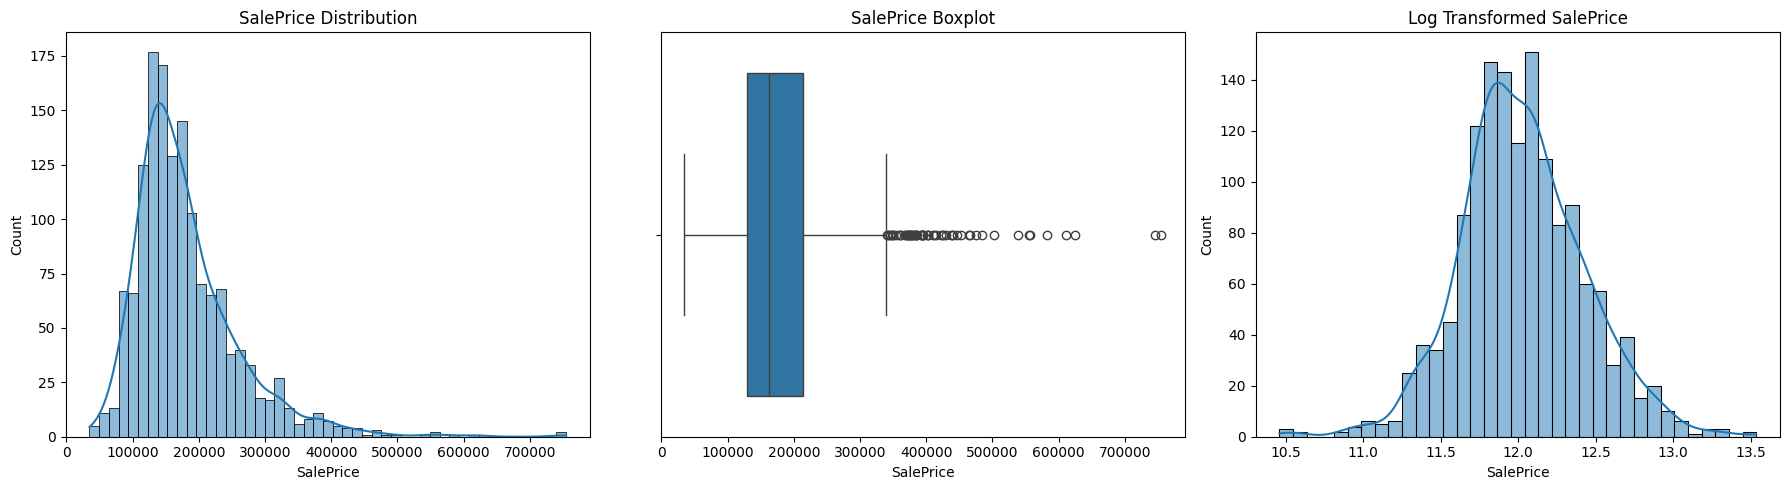

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")

sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")

sns.histplot(np.log(df["SalePrice"]), kde=True, ax=axes[2])
axes[2].set_title("Log Transformed SalePrice")

plt.tight_layout()
plt.show()


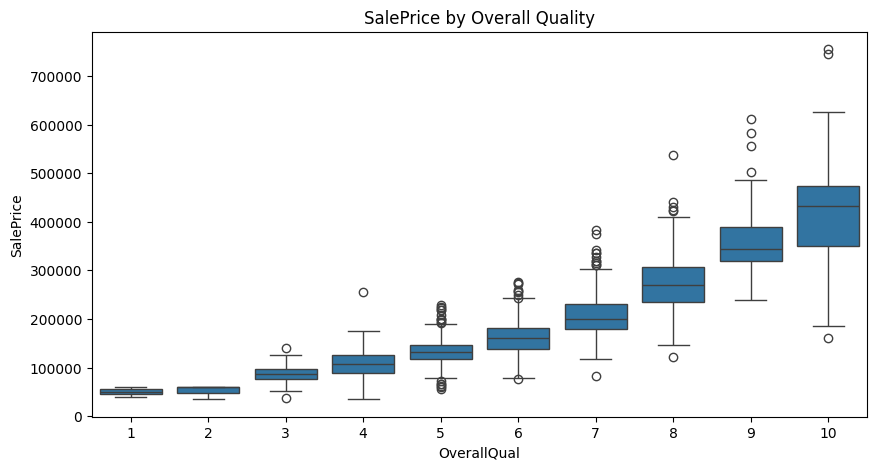

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.title("SalePrice by Overall Quality")
plt.show()

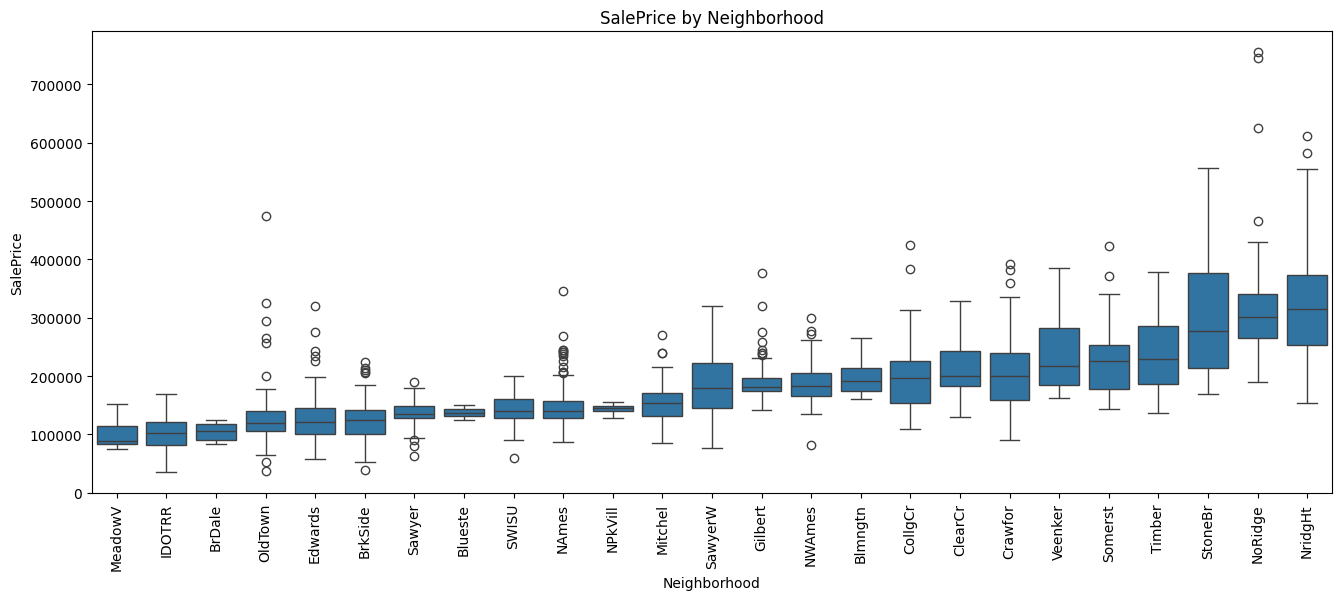

In [ ]:
plt.figure(figsize=(16, 6))

neighborhood_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=neighborhood_order)

plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood")
plt.show()


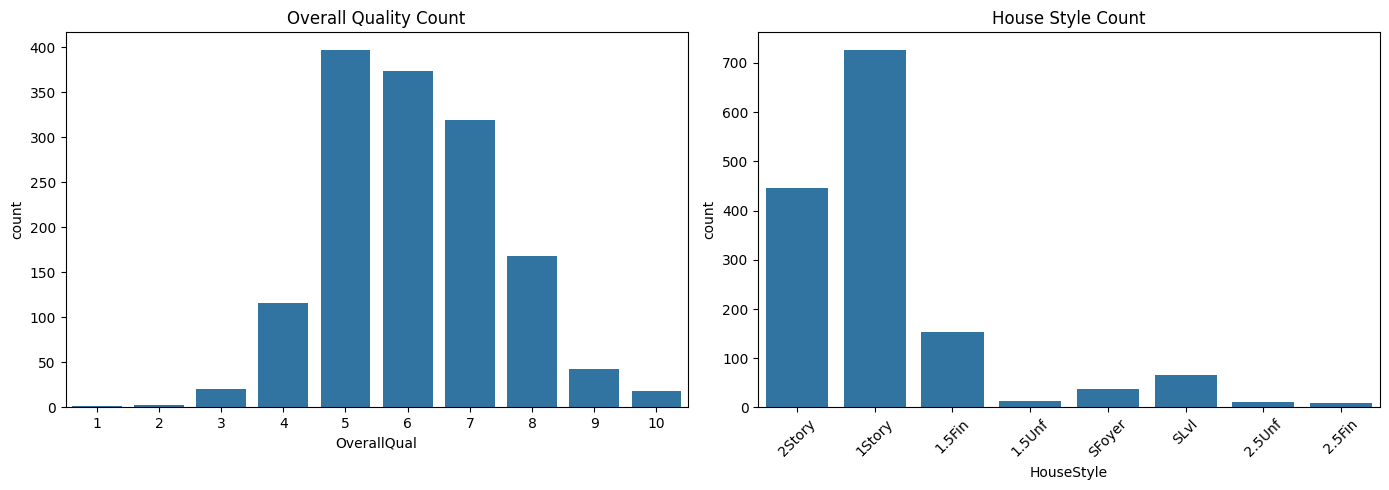

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="OverallQual", data=df, ax=axes[0])
axes[0].set_title("Overall Quality Count")

sns.countplot(x="HouseStyle", data=df, ax=axes[1])
axes[1].set_title("House Style Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

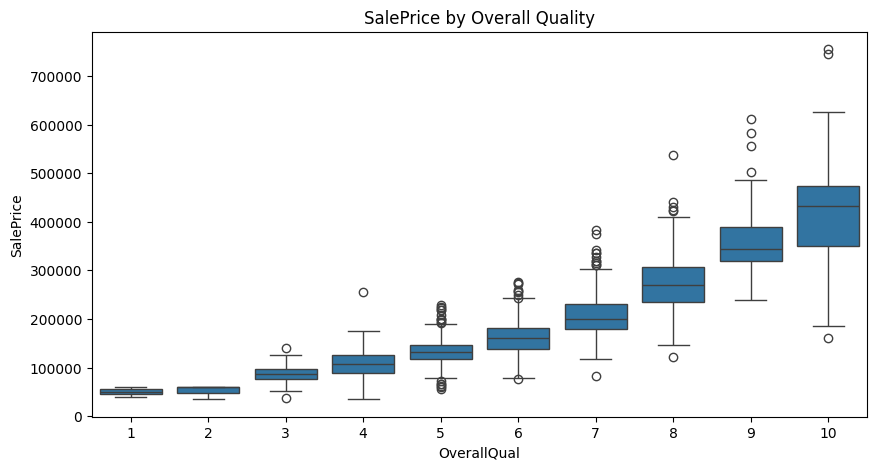

In [ ]:

plt.figure(figsize=(10, 5))

sns.boxplot(x="OverallQual", y="SalePrice", data=df)

plt.title("SalePrice by Overall Quality")
plt.show()


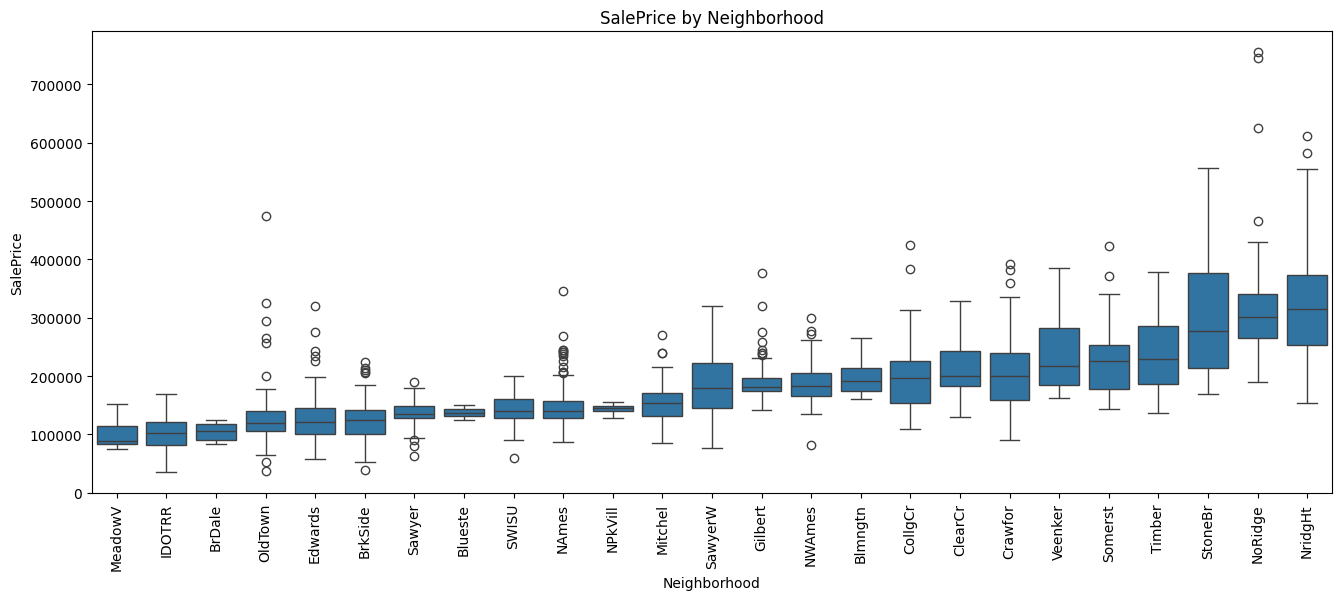

In [ ]:
plt.figure(figsize=(16, 6))

neighborhood_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=neighborhood_order)

plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood")
plt.show()

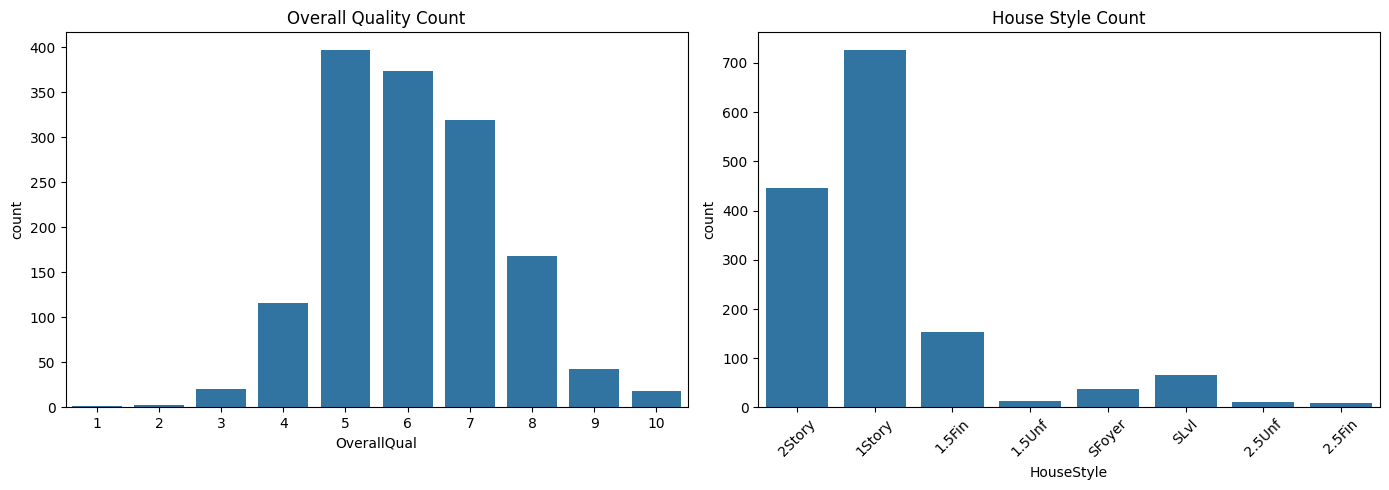

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="OverallQual", data=df, ax=axes[0])
axes[0].set_title("Overall Quality Count")

sns.countplot(x="HouseStyle", data=df, ax=axes[1])
axes[1].set_title("House Style Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
cov_matrix = df[numeric_cols].cov()
display(cov_matrix)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,177755.000000,198.968472,-108.390207,-1.398197e+05,-16.539068,5.915696,-1.618818e+02,-191.474297,-3.842688e+03,-9.661021e+02,...,-1.566468e+03,-1.332214e+01,74.450651,-576.428376,31.270391,966.275531,-1305.726525,24.133653,0.398561,-7.340732e+05
MSSubClass,198.968472,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-108.390207,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,...,2.587889e+02,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-139819.667238,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,-16.539068,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,5.915696,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,-161.881768,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,-191.474297,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,-3842.687941,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,...,3.626330e+03,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06
BsmtFinSF1,-966.102125,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07


In [ ]:
corr_matrix = df[numeric_cols].corr()
display(corr_matrix)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


In [ ]:
saleprice_corr = corr_matrix["SalePrice"].drop("SalePrice")

top10_corr = saleprice_corr.abs().sort_values(ascending=False).head(10)

print("Top 10 Features Correlated with SalePrice:")
print(saleprice_corr.loc[top10_corr.index])

Top 10 Features Correlated with SalePrice:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


In [ ]:
top3_features = top10_corr.index[:3]

for col in top3_features:
    print("\nFeature:", col)
    print("Covariance with SalePrice:", cov_matrix.loc[col, "SalePrice"])
    print("Correlation with SalePrice:", corr_matrix.loc[col, "SalePrice"])


Feature: OverallQual
Covariance with SalePrice: 86904.12583679946
Correlation with SalePrice: 0.7909816005838053

Feature: GrLivArea
Covariance with SalePrice: 29581866.743236575
Correlation with SalePrice: 0.7086244776126515

Feature: GarageCars
Covariance with SalePrice: 38020.18135897172
Correlation with SalePrice: 0.6404091972583519


In [ ]:
spearman_corr = df[numeric_cols].corr(method="spearman")
display(spearman_corr["SalePrice"].sort_values(ascending=False))

,SalePrice
SalePrice,1.000000
OverallQual,0.809829
GrLivArea,0.731310
GarageCars,0.690711
YearBuilt,0.652682
GarageArea,0.649379
FullBath,0.635957
TotalBsmtSF,0.602725
GarageYrBlt,0.593788
1stFlrSF,0.575408


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for column, order in ordinal_map.items():
    if column in df.columns:
        df[column] = pd.Categorical(df[column], categories=order, ordered=True)

# OverallQual is numeric in the file but represents an ordered quality rating.
summary_rows = []
for col in df.columns:
    examples = df[col].dropna().unique()[:5].tolist()
    if col == "OverallQual":
        var_type = "Ordinal (stored as numeric)"
    elif col in ordinal_map:
        var_type = "Ordinal"
    elif pd.api.types.is_numeric_dtype(df[col]):
        var_type = "Numerical"
    else:
        var_type = "Categorical"
    summary_rows.append({
        "Column": col,
        "Type": var_type,
        "Unique_Values": df[col].nunique(dropna=True),
        "Example_Values": examples
    })

variable_summary = pd.DataFrame(summary_rows)
display(variable_summary)
print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

## 3. Descriptive statistics

In [ ]:
display(df.describe().T)

for column in ["SalePrice", "GrLivArea", "LotArea"]:
    if column not in df.columns:
        continue
    s = df[column].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    print(f"\\n{column}")
    print("Mean:", round(s.mean(), 2))
    print("Median:", round(s.median(), 2))
    print("Mode:", s.mode().iloc[0])
    print("Standard deviation:", round(s.std(), 2))
    print("Variance:", round(s.var(), 2))
    print("Range:", round(s.max() - s.min(), 2))
    print("IQR:", round(q3 - q1, 2))
    print("Skewness:", round(s.skew(), 3))
    print("Kurtosis:", round(s.kurtosis(), 3))

for column in ["Neighborhood", "HouseStyle"]:
    if column in df.columns:
        print(f"\\nValue counts for {column}:")
        display(df[column].value_counts())
        print("Mode:", df[column].mode().tolist())

sale_mean = df["SalePrice"].mean()
sale_median = df["SalePrice"].median()
print("\\nSalePrice interpretation:")
if sale_mean > sale_median:
    print("Mean is greater than median, suggesting a right-skewed distribution.")
elif sale_mean < sale_median:
    print("Mean is less than median, suggesting a left-skewed distribution.")
else:
    print("Mean and median are equal; the distribution may be fairly balanced.")

## 4. Distribution analysis

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("Sale Price")

sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")

sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[2])
axes[2].set_title("Log-transformed SalePrice")
axes[2].set_xlabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()

print("Original SalePrice skewness:", round(df["SalePrice"].skew(), 3))
print("Log SalePrice skewness:", round(np.log1p(df["SalePrice"]).skew(), 3))

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice")
plt.title("Sale Price by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()

neighborhood_order = df.groupby("Neighborhood", observed=True)["SalePrice"].median().sort_values().index
plt.figure(figsize=(15, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=neighborhood_order)
plt.title("Sale Price by Neighborhood (ordered by median)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="OverallQual", ax=axes[0])
axes[0].set_title("Count of Overall Quality Ratings")
sns.countplot(data=df, x="HouseStyle", ax=axes[1])
axes[1].set_title("Count of House Styles")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 5. Correlation and covariance

In [30]:
cov_matrix = df[numeric_cols].cov()
display(cov_matrix)

corr_matrix = df[numeric_cols].corr()
display(corr_matrix)

saleprice_corr = corr_matrix["SalePrice"].drop("SalePrice")

top10_corr = saleprice_corr.abs().sort_values(ascending=False).head(10)

print("Top 10 Features Correlated with SalePrice:")
print(saleprice_corr.loc[top10_corr.index])

top3_features = top10_corr.index[:3]

for col in top3_features:
    print("\nFeature:", col)
    print("Covariance with SalePrice:", cov_matrix.loc[col, "SalePrice"])
    print("Correlation with SalePrice:", corr_matrix.loc[col, "SalePrice"])




,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,177755.000000,198.968472,-108.390207,-1.398197e+05,-16.539068,5.915696,-1.618818e+02,-191.474297,-3.842688e+03,-9.661021e+02,...,-1.566468e+03,-1.332214e+01,74.450651,-576.428376,31.270391,966.275531,-1305.726525,24.133653,0.398561,-7.340732e+05
MSSubClass,198.968472,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-108.390207,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,...,2.587889e+02,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-139819.667238,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,-16.539068,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,5.915696,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,-161.881768,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,-191.474297,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,-3842.687941,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,...,3.626330e+03,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06
BsmtFinSF1,-966.102125,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07


**Observation**

OverallQual, GrLivArea, and GarageCars are among the features strongly correlated with SalePrice.



OverallQual generally has the strongest positive correlation with SalePrice.



Correlation is easier to compare because its values range from -1 to +1, whereas covariance depends on the scale of the variables.



Correlation does not imply causation. Two variables may be related without one directly causing the other.



GarageArea and GarageCars are strongly correlated because larger garages generally accommodate more cars.**bold text**

In [ ]:
numeric_data = df.select_dtypes(include=np.number)
corr_matrix = numeric_data.corr(method="pearson")
cov_matrix = numeric_data.cov()

top_corr = corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False)
top10_features = top_corr.head(10).index.tolist()

print("Top 10 numerical features correlated with SalePrice:")
display(pd.DataFrame({
    "Correlation": corr_matrix.loc[top10_features, "SalePrice"],
    "Covariance": cov_matrix.loc[top10_features, "SalePrice"]
}).sort_values("Correlation", key=abs, ascending=False))

print("Correlation is easier to compare because it is standardized between -1 and +1.")
print("Covariance depends on the units and scale of the two variables.")

# Example of two features that are strongly related to each other.
if {"GarageArea", "GarageCars"}.issubset(corr_matrix.columns):
    print("Correlation between GarageArea and GarageCars:",
          round(corr_matrix.loc["GarageArea", "GarageCars"], 3))

if {"OverallQual", "SalePrice"}.issubset(df.columns):
    print("Spearman correlation of OverallQual with SalePrice:",
          round(df["OverallQual"].corr(df["SalePrice"], method="spearman"), 3))

## 6. Scatter plots and pair plot

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)

outliers = df[df["GrLivArea"] > 4000]

plt.scatter(outliers["GrLivArea"], outliers["SalePrice"], color="red", label="Large Houses")

plt.title("GrLivArea vs SalePrice")
plt.xlabel("Living Area")
plt.ylabel("Sale Price")
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(x="TotalBsmtSF", y="SalePrice", data=df)

plt.title("Basement Area vs SalePrice")
plt.xlabel("Total Basement Area")
plt.ylabel("Sale Price")
plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(x="YearBuilt", y="SalePrice", data=df)

plt.title("Year Built vs SalePrice")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")
plt.show()

selected_features = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

sns.pairplot(
    df[selected_features],
    diag_kind="kde"
)

plt.show()

1. GrLivArea and SalePrice generally show a positive relationship. Larger living areas tend to have higher prices.
2. TotalBsmtSF generally has a positive relationship with SalePrice.
3. Houses built in more recent years tend to have higher sale prices.
4. The pair plot helps identify relationships, trends, and possible outliers among multiple numerical features.
5. A few houses with very large living areas may have unusually low sale prices.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", ax=axes[0])
axes[0].set_title("Living Area vs Sale Price")

sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", ax=axes[1])
axes[1].set_title("Basement Area vs Sale Price")

sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", ax=axes[2])
axes[2].set_title("Year Built vs Sale Price")

plt.tight_layout()
plt.show()

# Flag unusually large living areas with comparatively low sale prices for inspection.
unusual = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 200000)]
print("Very large homes with low sale prices (inspect these rows):", len(unusual))
display(unusual[["Id", "GrLivArea", "SalePrice", "OverallQual"]].head(20))

pair_cols = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
pair_data = df[pair_cols].dropna()
if len(pair_data) > 500:
    pair_data = pair_data.sample(500, random_state=42)
sns.pairplot(pair_data, diag_kind="kde")
plt.show()

## 7. Correlation heatmap

In [ ]:
top10_features = saleprice_corr.abs().sort_values(ascending=False).head(10).index

top10_corr_matrix = df[top10_features].corr()

mask = np.triu(np.ones_like(top10_corr_matrix, dtype=bool))

plt.figure(figsize=(12, 8))

sns.heatmap(
    top10_corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Top 10 Features")
plt.show()



The heatmap shows the strength and direction of relationships between numerical features.



Values close to +1 indicate a strong positive correlation.



Values close to -1 indicate a strong negative correlation.



Values close to 0 indicate a weak linear relationship.



Features such as OverallQual and GrLivArea show strong positive relationships with SalePrice.

In [ ]:
heatmap_cols = ["SalePrice"] + top10_features
corr_top = df[heatmap_cols].corr()

mask = np.triu(np.ones_like(corr_top, dtype=bool), k=1)
plt.figure(figsize=(12, 9))
sns.heatmap(corr_top, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True)
plt.title("Top 10 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()

## 8. Outlier detection: IQR and Z-score

In [ ]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[(data[column] < lower) | (data[column] > upper)]


for col in ["GrLivArea", "SalePrice"]:
    outliers = detect_outliers_iqr(df, col)
    print(col, "IQR Outliers:", len(outliers))

    from scipy import stats

for col in ["GrLivArea", "SalePrice"]:
    z_scores = np.abs(stats.zscore(df[col]))
    outliers = df[z_scores > 3]

    print(col, "Z-score Outliers:", len(outliers))

    iqr_outliers = detect_outliers_iqr(df, "GrLivArea").index

z_scores = np.abs(stats.zscore(df["GrLivArea"]))
z_outliers = df[z_scores > 3].index

print("IQR Outliers:", len(iqr_outliers))
print("Z-score Outliers:", len(z_outliers))
print("Common Outliers:", len(set(iqr_outliers) & set(z_outliers)))


plt.figure(figsize=(12, 5))

sns.boxplot(x=df["GrLivArea"])
plt.title("Outliers in GrLivArea")
plt.show()


plt.figure(figsize=(10, 6))

sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)

outliers = df[df["GrLivArea"] > 4000]

plt.scatter(
    outliers["GrLivArea"],
    outliers["SalePrice"],
    color="red",
    label="Potential Outliers"
)

plt.title("GrLivArea vs SalePrice with Potential Outliers")
plt.legend()
plt.show()

The IQR and Z-score methods identify unusually high or low values in the dataset.



The IQR method detects outliers based on the spread of the data, while the Z-score method uses standard deviations from the mean.



Some outliers may represent genuine houses rather than incorrect data.



Outliers should not be removed automatically because they may contain useful information.



Large houses with unusually low sale prices should be investigated before deciding whether to remove them.

In [ ]:
def iqr_outliers(series):
    s = series.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return s[(s < lower) | (s > upper)].index

def zscore_outliers(series, threshold=3):
    s = series.dropna()
    z = (s - s.mean()) / s.std()
    return s[abs(z) > threshold].index

outlier_summary = []
for column in ["GrLivArea", "SalePrice"]:
    iqr_idx = set(iqr_outliers(df[column]))
    z_idx = set(zscore_outliers(df[column]))
    outlier_summary.append({
        "Column": column,
        "IQR_Outliers": len(iqr_idx),
        "ZScore_Outliers": len(z_idx),
        "Overlap": len(iqr_idx & z_idx)
    })

display(pd.DataFrame(outlier_summary))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df["GrLivArea"], ax=axes[0])
axes[0].set_title("GrLivArea Outliers")
sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Outliers")
plt.tight_layout()
plt.show()

iqr_idx = iqr_outliers(df["GrLivArea"])
z_idx = zscore_outliers(df["GrLivArea"])
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", color="steelblue", label="Other rows")
plt.scatter(df.loc[list(iqr_idx), "GrLivArea"], df.loc[list(iqr_idx), "SalePrice"],
            label="IQR flagged", marker="x")
plt.title("Living Area vs Sale Price: IQR-Flagged Points")
plt.xlabel("Above-ground Living Area")
plt.ylabel("Sale Price")
plt.legend()
plt.show()

print("Z-score can flag fewer points for skewed data because it uses mean and standard deviation,")
print("which are influenced by extreme values. IQR is based on quartiles and is more robust.")
print("Outliers are flagged for investigation, not automatically deleted.")

## 9. Data quality checks and missing values

In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

categorical_missing = ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType"]

for col in categorical_missing:
    df[col] = df[col].fillna("None")

    df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

    missing_values = df.isnull().sum()

print("Remaining Missing Values:")
print(missing_values[missing_values > 0])

print("YearBuilt greater than YrSold:")
print(df[df["YearBuilt"] > df["YrSold"]])

print("Negative area values:")
area_columns = ["GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea"]

for col in area_columns:
    print(col, ":", (df[col] < 0).sum())

uplicate records are checked to ensure that the dataset does not contain repeated rows.



Missing values in columns such as PoolQC, Alley, Fence, FireplaceQu, and GarageType may indicate that these features are absent.



Missing LotFrontage values are filled using the median of the respective neighborhood.



Remaining missing values are checked after cleaning.



Impossible values, such as a house built after its sale year or negative area measurements, are investigated.



Data cleaning improves the quality and reliability of the dataset for analysis.

In [ ]:
# Work on a copy so the original data remains available.
df_clean = df.copy()

duplicate_count = df_clean.duplicated().sum()
print("Duplicate rows:", duplicate_count)
if duplicate_count:
    df_clean = df_clean.drop_duplicates()
print("Shape after duplicate check:", df_clean.shape)

# Standardize whitespace in text columns without changing category spelling/case.
text_cols = df_clean.select_dtypes(include="object").columns
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

# These missing values usually mean that the feature is absent in this dataset.
absent_feature_cols = [
    "PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "BsmtQual",
    "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType"
]
for col in absent_feature_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("None")

# Fill remaining categorical missing values with the mode.
remaining_categorical = df_clean.select_dtypes(include=["object", "category"]).columns
for col in remaining_categorical:
    if df_clean[col].isna().any():
        mode_values = df_clean[col].mode(dropna=True)
        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(mode_values.iloc[0])

# Fill numeric missing values with neighborhood median where possible,
# otherwise use the column median.
for col in df_clean.select_dtypes(include=np.number).columns:
    if df_clean[col].isna().any():
        if col == "LotFrontage" and "Neighborhood" in df_clean.columns:
            df_clean[col] = df_clean[col].fillna(
                df_clean.groupby("Neighborhood")[col].transform("median")
            )
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values remaining:", int(df_clean.isna().sum().sum()))
remaining_missing = df_clean.isna().sum()
display(remaining_missing[remaining_missing > 0])

# Basic impossible-value checks.
if {"YearBuilt", "YrSold"}.issubset(df_clean.columns):
    print("Rows where YearBuilt > YrSold:",
          int((df_clean["YearBuilt"] > df_clean["YrSold"]).sum()))

area_cols = [c for c in ["GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea"] if c in df_clean.columns]
for col in area_cols:
    print(f"Negative values in {col}:", int((df_clean[col] < 0).sum()))

print("Cleaning decisions: missing categorical values in absence-related columns are marked 'None';")
print("remaining categorical values use the mode; numeric values use median (LotFrontage uses")
print("neighborhood median first). These choices are documented rather than silently dropping rows.")

## 10. Final dashboard

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Average SalePrice by YearBuilt
yearly_price = df.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(yearly_price.index, yearly_price.values)
axes[0, 0].set_title("Average SalePrice by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average SalePrice")

# 2. Top 10 Neighborhoods by Mean SalePrice
top_neighborhoods = (
    df.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

sns.barplot(
    x=top_neighborhoods.values,
    y=top_neighborhoods.index,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Top 10 Neighborhoods by Average SalePrice")
axes[0, 1].set_xlabel("Average SalePrice")

# 3. SalePrice Distribution with Mean and Median
sns.histplot(df["SalePrice"], kde=True, ax=axes[1, 0])

axes[1, 0].axvline(
    df["SalePrice"].mean(),
    linestyle="--",
    label="Mean"
)

axes[1, 0].axvline(
    df["SalePrice"].median(),
    linestyle="-",
    label="Median"
)

axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].legend()

# 4. GrLivArea vs SalePrice colored by OverallQual
sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Living Area vs SalePrice by Overall Quality")

plt.suptitle("Ames Housing – Exploratory Data Analysis Dashboard", fontsize=16)

plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300)
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: average sale price by year built.
year_price = df_clean.groupby("YearBuilt", as_index=False)["SalePrice"].mean()
axes[0, 0].plot(year_price["YearBuilt"], year_price["SalePrice"], label="Average price")
axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()

# Panel 2: top 10 neighborhoods by average sale price.
neighborhood_price = (
    df_clean.groupby("Neighborhood")["SalePrice"].mean()
    .sort_values(ascending=False).head(10).sort_values()
)
axes[0, 1].barh(neighborhood_price.index, neighborhood_price.values)
axes[0, 1].set_title("Top 10 Neighborhoods by Average Sale Price")
axes[0, 1].set_xlabel("Average Sale Price")

# Panel 3: sale price distribution with mean and median.
sns.histplot(df_clean["SalePrice"], kde=True, ax=axes[1, 0])
axes[1, 0].axvline(df_clean["SalePrice"].mean(), linestyle="--",
                   label="Mean")
axes[1, 0].axvline(df_clean["SalePrice"].median(), linestyle=":",
                   label="Median")
axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].legend()

# Panel 4: living area vs price, coloured by overall quality.
sns.scatterplot(data=df_clean, x="GrLivArea", y="SalePrice",
                hue="OverallQual", palette="viridis", ax=axes[1, 1])
axes[1, 1].set_title("Living Area vs Sale Price by Overall Quality")

fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("Dashboard saved as eda_dashboard.png")

## 11. Conclusions (generated from the dataset)

Conclusion
1. SalePrice has a right-skewed distribution, with a few houses having very high prices.
2. OverallQual and GrLivArea are among the strongest features related to SalePrice.
3. House prices vary across different neighborhoods.
4. Larger living areas generally have higher sale prices.
5. Outlier detection helped identify unusual observations in the dataset.
6. Missing values were handled according to the meaning of each feature.
7. The dashboard summarizes the important patterns and relationships found during the analysis.
Limitations
1. The analysis is based on only one housing dataset.
2. Correlation does not establish cause-and-effect relationships.
3. Some missing values and outliers require further investigation.
4. The analysis does not predict future house prices.

In [ ]:
print("EDA CONCLUSIONS")
print("----------------")
print(f"Dataset contains {df.shape[0]} rows and {df.shape[1]} columns.")
print(f"Average sale price: ${df['SalePrice'].mean():,.2f}")
print(f"Median sale price: ${df['SalePrice'].median():,.2f}")
print(f"SalePrice skewness: {df['SalePrice'].skew():.3f}")

print("\\nStrongest numerical relationships with SalePrice:")
display(corr_matrix["SalePrice"].drop("SalePrice").sort_values(
    key=abs, ascending=False
).head(5).to_frame("Correlation"))

quality_prices = df.groupby("OverallQual")["SalePrice"].median()
print("\\nMedian sale price by overall quality:")
display(quality_prices.to_frame("Median SalePrice"))

neighborhood_medians = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)
print("\\nFive neighborhoods with highest median sale prices:")
display(neighborhood_medians.head(5).to_frame("Median SalePrice"))

print("\\nLimitations:")
print("- This analysis describes associations and does not prove causation.")
print("- Outliers are identified for review and are not automatically errors.")
print("- Results describe this dataset and may not represent every housing market.")